# H5 · Pro cae en el brazo B porque rehace el grafo desde la pizarra y el transcript, y no es ruido

**Hipótesis.** La caída de Gemini Pro en el brazo B (H2) y su subida al quitar la pizarra y el
transcript (H4) no son ruido de una corrida: Pro no usa el World Model como inventario, vuelve
a leer la pizarra y la narración y arma su propio grafo.

**Veredicto: se sostiene, y el efecto se repite.**

- La segunda corrida de Pro da lo mismo en las dos condiciones: 68,12 con las tres entradas
  (la primera dio 71,49) y 88,75 con solo el World Model (la primera dio 87,59). El efecto de
  quitar las dos entradas es +16,10 en la primera pareja y +20,63 en la segunda.
- De las 113 aristas que le sobran a Pro en el brazo B, 65 son las mismas que dibuja en el
  brazo A, donde solo tiene la lectura de la pizarra. En la réplica, 72 de 117.
  Claude también repite las suyas (42 de 56), pero añade la mitad que Pro y casi no inventa
  servicios; Flash apenas añade (25).
- Su razonamiento describe la pizarra ("The visual board shows…") y cita el audio para
  justificar aristas, en vez de partir del World Model.

**Ruido medido.** Pro contra sí mismo, a temperatura 0: −3,36 puntos con las tres entradas
(IC 95 % [−6,84, −0,29]) y +1,17 con solo el World Model. Flash contra sí mismo en el brazo B: −2,02.

## Archivos usados, cómo se generaron y dónde quedaron

| corrida | cómo se generó | dónde quedó |
|---|---|---|
| Pro, brazo B completo | `.venv/Scripts/python scripts/ablation/rerun_panel.py --prompt stage2_v6_corrected__cell9.txt --panel 30 --oracle oracle_gt --model gemini-3.1-pro-preview --out …` | `reports/pro_vs_flash/pro_gemini-3.1-pro-preview_oracle-gt/` |
| Pro, brazo B completo · réplica 2 | la misma, con `--replicate 2` | `reports/pro_vs_flash/pro_gemini-3.1-pro-preview_oracle-gt_rep2/` |
| Pro, solo World Model | `… --oracle oracle_gt --no-transcript --no-image --model gemini-3.1-pro-preview --out …` | `reports/pro_vs_flash/pro_gemini-3.1-pro-preview_oracle-gt_solo-wm/` |
| Pro, solo World Model · réplica 2 | la misma, con `--replicate 2` | `reports/pro_vs_flash/pro_gemini-3.1-pro-preview_oracle-gt_solo-wm_rep2/` |
| Pro, Flash y Claude en el brazo A | ver H1 | `reports/pro_vs_flash/*_stage1-manual/`, `reports/claude/` |
| Flash y Claude en el brazo B | ver H2 | `reports/ablation/*oracle-oracle_gt*/`, `reports/claude_oracle_gt/` |

El razonamiento de cada modelo está en el campo `analysis.step_by_step_reasoning` de cada fila
de `run.json`. Los logs de las réplicas están en `reports/pro_vs_flash/pro_oracle_gt_rep2.log` y
`pro_oracle_gt_solo_wm_rep2.log`. Figuras de este notebook: `hipotesis/figuras/H5_*.png`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import comun as c

c.estilo()
from collections import Counter

TODAS = [k for k in c.RUNS if c.existe(k)]
n, distintas = c.verificar(TODAS)
print(f"Control: el F1 de aristas recalculado aquí coincide con el del evaluador en {n - distintas} de {n} filas.")
c.tabla_resumen([k for k in TODAS if c.modelo(k) == "pro"])

Control: el F1 de aristas recalculado aquí coincide con el del evaluador en 898 de 900 filas.


corrida,F1 servicios,F1 aristas,aristas / GT,faltan,sobran,precisión,recall,servicios inventados,videos perfectos,carpeta
Gemini 3.1 Pro,86.46,59.80,11.40 / 12.03,152,133,61.1,57.9,35,0,reports/pro_vs_flash/pro_gemini-3.1-pro-preview_stage1-manual
Gemini 3.1 Pro,93.54,71.49,12.63 / 12.03,95,113,70.2,73.7,19,2,reports/pro_vs_flash/pro_gemini-3.1-pro-preview_oracle-gt
Gemini 3.1 Pro · réplica 2,92.43,68.12,12.20 / 12.03,112,117,68.0,69.0,22,1,reports/pro_vs_flash/pro_gemini-3.1-pro-preview_oracle-gt_rep2
Gemini 3.1 Pro,99.04,87.59,10.40 / 12.03,69,20,93.6,80.9,2,14,reports/pro_vs_flash/pro_gemini-3.1-pro-preview_oracle-gt_solo-wm
Gemini 3.1 Pro · réplica 2,99.04,88.75,10.57 / 12.03,63,19,94.0,82.5,2,14,reports/pro_vs_flash/pro_gemini-3.1-pro-preview_oracle-gt_solo-wm_rep2
Gemini 3.1 Pro,85.04,56.07,11.30 / 12.03,168,146,56.9,53.5,37,0,reports/pro_vs_flash/pro_gemini-3.1-pro-preview
Gemini 3.1 Pro,86.45,57.52,10.97 / 12.03,166,134,59.3,54.0,32,0,reports/prompt_v9/pro_produccion
Gemini 3.1 Pro,97.81,93.72,12.93 / 12.03,9,36,90.7,97.5,6,17,reports/prompt_v9/pro_oracle-gt
Gemini 3.1 Pro · réplica 2,98.18,94.52,12.70 / 12.03,9,29,92.4,97.5,5,20,reports/prompt_v9/pro_oracle-gt_rep2


## 1 · De dónde salen las aristas que Pro añade

Para cada modelo: las aristas que le sobran en el brazo B y cuántas de ellas son las mismas que
dibuja en el brazo A, donde solo tiene la lectura de la pizarra.

modelo,sobran en brazo B,también en su brazo A,%
Gemini 3.1 Pro,113,65,58 %
Gemini 3.6 Flash,25,13,52 %
Claude Opus 5.5,56,42,75 %


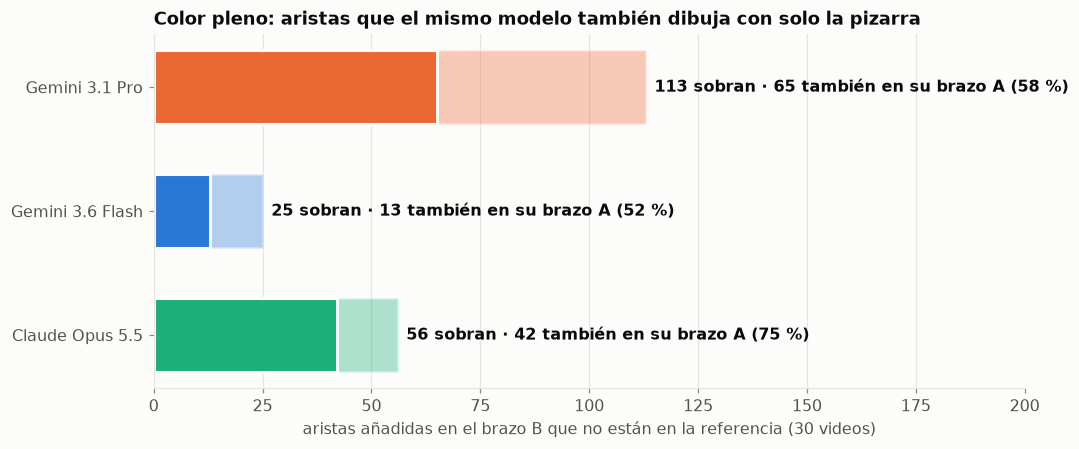

In [2]:
def sobrantes(k):
    return {v: c.gen(f) - c.gt(v)[1] for v, f in c.filas(k).items()}

fig, ax = plt.subplots(figsize=(10, 4.2))
filas_tabla = []
for y, m in enumerate(["claude", "flash", "pro"]):
    sob, armA = sobrantes(f"B_{m}"), {v: c.gen(f) for v, f in c.filas(f"A_{m}").items()}
    total = sum(sum(s.values()) for s in sob.values())
    enA = sum(sum((s & armA[v]).values()) for v, s in sob.items())
    ax.barh(y, total, height=0.6, color=c.COLOR[m], alpha=0.35, edgecolor=c.FONDO, linewidth=2)
    ax.barh(y, enA, height=0.6, color=c.COLOR[m], edgecolor=c.FONDO, linewidth=2)
    ax.text(total + 2, y, f"{total} sobran · {enA} también en su brazo A ({100 * enA / total:.0f} %)", va="center", fontweight="bold")
    filas_tabla.append([c.NOMBRE[m], total, enA, f"{100 * enA / total:.0f} %"])
ax.set_yticks(range(3), [c.NOMBRE[m] for m in ["claude", "flash", "pro"]])
ax.set_xlim(0, 200)
ax.set_xlabel("aristas añadidas en el brazo B que no están en la referencia (30 videos)")
ax.set_title("Color pleno: aristas que el mismo modelo también dibuja con solo la pizarra")
ax.grid(axis="y", visible=False)
fig.tight_layout()
c.guardar(fig, "H5_origen_de_las_sobrantes")
c.Tabla(["modelo", "sobran en brazo B", "también en su brazo A", "%"], filas_tabla[::-1])

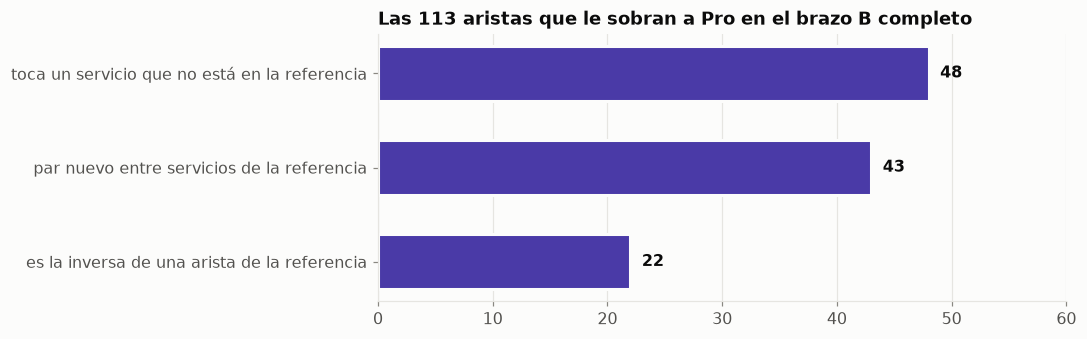

In [3]:
sob = sobrantes("B_pro")
clase = Counter()
for v, s in sob.items():
    servicios, ref = set(c.gt(v)[0].values()), c.gt(v)[1]
    for (a, b), n in s.items():
        if a not in servicios or b not in servicios:
            clase["toca un servicio que no está en la referencia"] += n
        elif ref[(b, a)] > 0:
            clase["es la inversa de una arista de la referencia"] += n
        else:
            clase["par nuevo entre servicios de la referencia"] += n
orden = sorted(clase, key=clase.get)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.barh(orden, [clase[k] for k in orden], height=0.58, color=c.SOBRA, edgecolor=c.FONDO, linewidth=2)
for y, k in enumerate(orden):
    ax.text(clase[k] + 1, y, str(clase[k]), va="center", fontweight="bold")
ax.set_xlim(0, 60)
ax.set_title(f"Las {sum(clase.values())} aristas que le sobran a Pro en el brazo B completo")
ax.grid(axis="y", visible=False)
fig.tight_layout()
c.guardar(fig, "H5_clases_de_sobrantes")

## 2 · Lo que dice el propio modelo

In [4]:
d = c.pareado("B_pro", "Bwm_pro")["d"]
vid = max(d, key=d.get)
f = c.filas("B_pro")[vid]
print(f"{vid} · servicios inventados: {f['services_hallucinated']} · omitidos: {f['services_missing']}\n")
print(f["analysis"]["step_by_step_reasoning"][:1400] + " …")

hMK2NJ-q9nc · servicios inventados: ['AutoScaling', 'OnPremDC'] · omitidos: ['UserCompanyDataStream']

1. **Node Identification & Normalization**: The visual board shows S3, CloudFormation, an Auto Scaling Group (ASG), multiple EC2 instances, Direct Connect, a building labeled 'TWD/CNN Center', and two satellite dishes labeled 'NYC' and 'ATL'. 
2. **Dynamic Logical Fusion**: The three EC2 instances represent the same logical playout workload distributed across three Availability Zones in US East 1. They are fused into a single logical `EC2` node.
3. **Audio-Driven Expansion & Mapping**: The 'TWD/CNN Center' is mapped to `OnPremDC` as it represents the Atlanta on-premises facility. The 'NYC' and 'ATL' satellite dishes represent uplinks for distribution to affiliates and are mapped to `UserCompanyEdge`. The audio explicitly mentions that master files are QC'd in Atlanta and uploaded to S3 via Aspera, which justifies adding a data flow from the `OnPremDC` to `S3`.
4. **Flow 1 (Primary Pla

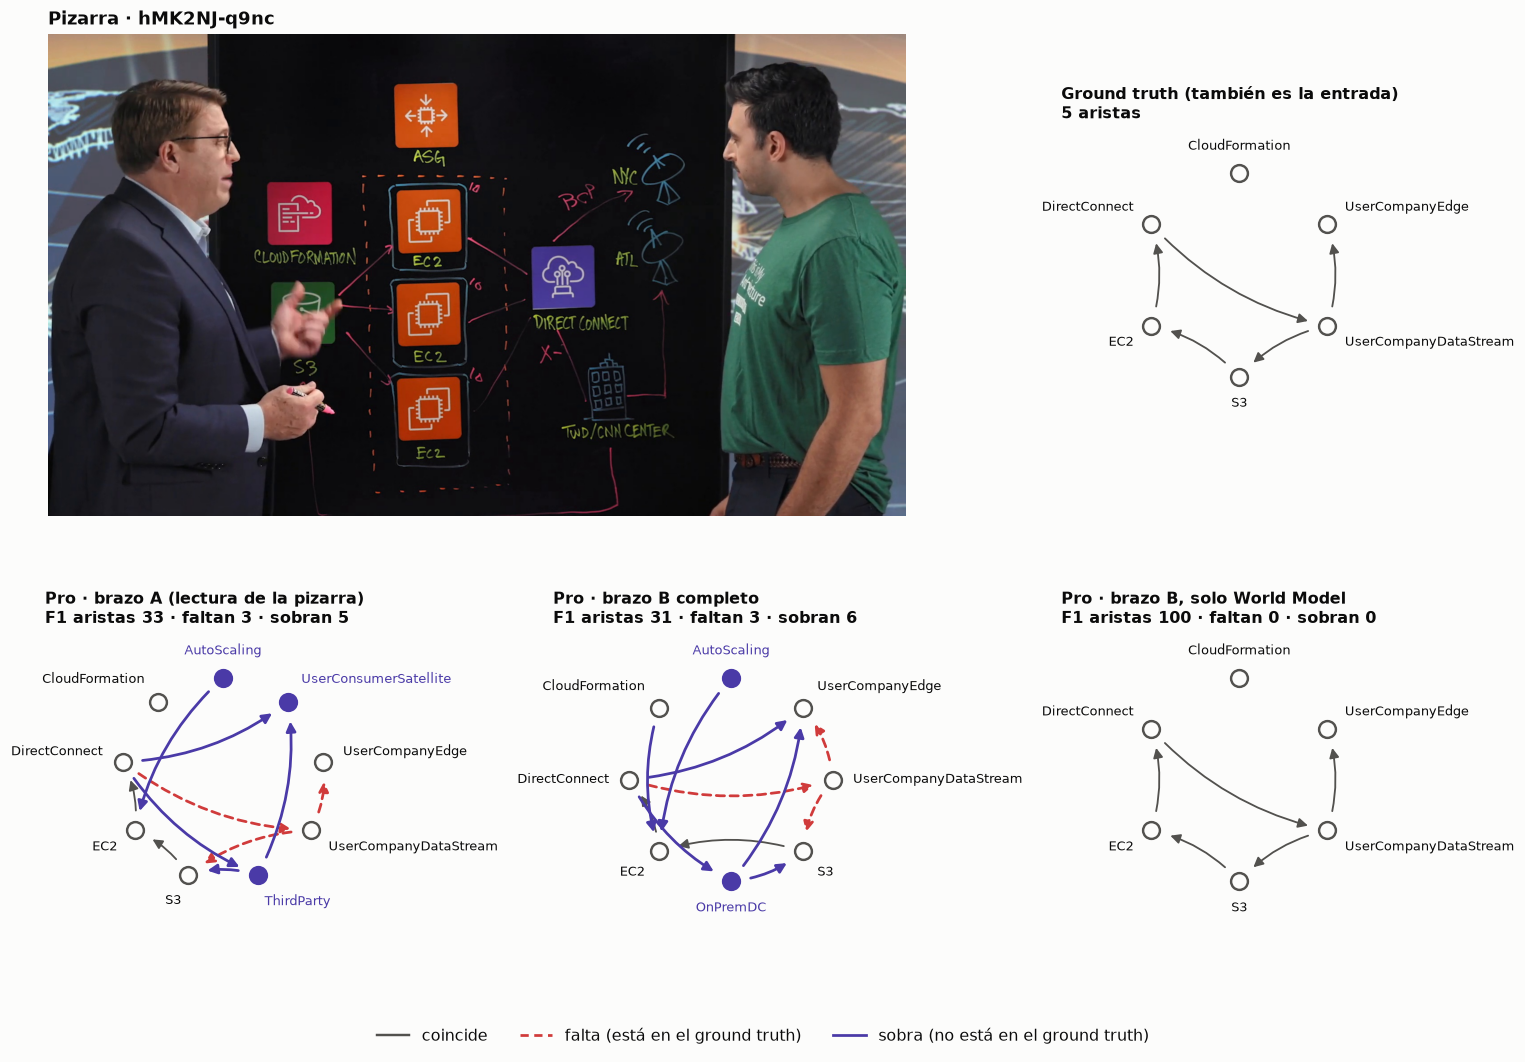

In [5]:
fig = plt.figure(figsize=(14, 9.5))
gs = fig.add_gridspec(2, 3)
c.pizarra(fig.add_subplot(gs[0, :2]), vid)
c.grafo(fig.add_subplot(gs[0, 2]), vid, titulo="Ground truth (también es la entrada)")
c.grafo(fig.add_subplot(gs[1, 0]), vid, c.filas("A_pro")[vid], "Pro · brazo A (lectura de la pizarra)")
c.grafo(fig.add_subplot(gs[1, 1]), vid, c.filas("B_pro")[vid], "Pro · brazo B completo")
c.grafo(fig.add_subplot(gs[1, 2]), vid, c.filas("Bwm_pro")[vid], "Pro · brazo B, solo World Model")
c.leyenda_grafo(fig)
fig.tight_layout()
c.guardar(fig, "H5_ejemplo")

## 3 · Cuánto ruido tiene cada modelo

Cada punto es una corrida completa del panel de 30. Dos puntos del mismo color en la misma
columna son réplicas: la distancia entre ellos es el ruido de ese modelo en esa condición.

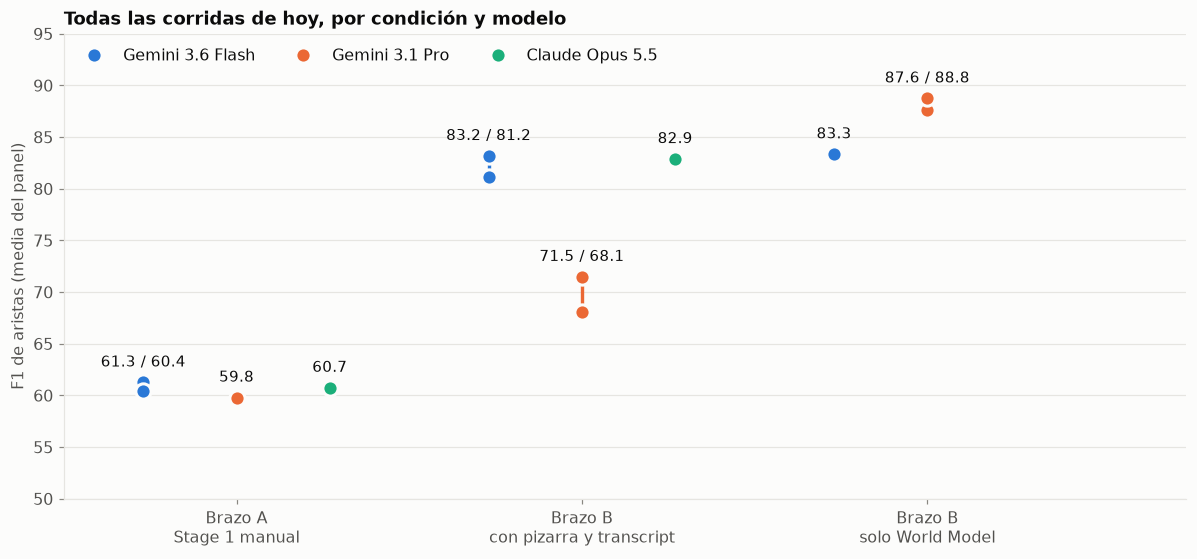

In [6]:
cond = [("A", "Brazo A\nStage 1 manual"), ("B", "Brazo B\ncon pizarra y transcript"), ("Bwm", "Brazo B\nsolo World Model")]
desplaz = {"flash": -0.27, "pro": 0.0, "claude": 0.27}
fig, ax = plt.subplots(figsize=(11, 5.2))
for x, (pref, _) in enumerate(cond):
    for m in ["flash", "pro", "claude"]:
        ks = [k for k in TODAS if k.split("_")[0] == pref and c.modelo(k) == m]
        ys = [c.resumen(k)["edge"] for k in ks]
        if not ys:
            continue
        xx = x + desplaz[m]
        ax.plot([xx] * len(ys), ys, color=c.COLOR[m], linewidth=2.2, solid_capstyle="round")
        ax.plot([xx] * len(ys), ys, "o", color=c.COLOR[m], markersize=10, markeredgecolor=c.FONDO, markeredgewidth=2,
                label=c.NOMBRE[m] if x == 0 else None)
        ax.text(xx, max(ys) + 1.2, " / ".join(f"{y:.1f}" for y in ys), va="bottom", ha="center", fontsize=9.5)
ax.set_xticks(range(len(cond)), [n for _, n in cond])
ax.set_xlim(-0.5, len(cond) - 0.25)
ax.set_ylim(50, 95)
ax.set_ylabel("F1 de aristas (media del panel)")
ax.set_title("Todas las corridas de hoy, por condición y modelo")
ax.legend(loc="upper left", ncol=3)
ax.grid(axis="x", visible=False)
fig.tight_layout()
c.guardar(fig, "H5_todas_las_corridas")

comparación (B − A),Δ,IC 95 %,gana / pierde / empata,p (signos)
Gemini 3.6 Flash · réplica 2 − Gemini 3.6 Flash,-0.87,"[-2.77, +0.83]",3 / 5 / 22,0.727
Gemini 3.6 Flash · réplica 2 − Gemini 3.6 Flash,-2.02,"[-4.36, +0.13]",6 / 14 / 10,0.115
Gemini 3.1 Pro · réplica 2 − Gemini 3.1 Pro,-3.36,"[-6.84, -0.29]",5 / 8 / 17,0.581
Gemini 3.1 Pro · réplica 2 − Gemini 3.1 Pro,+1.17,"[+0.00, +2.88]",3 / 0 / 27,0.250


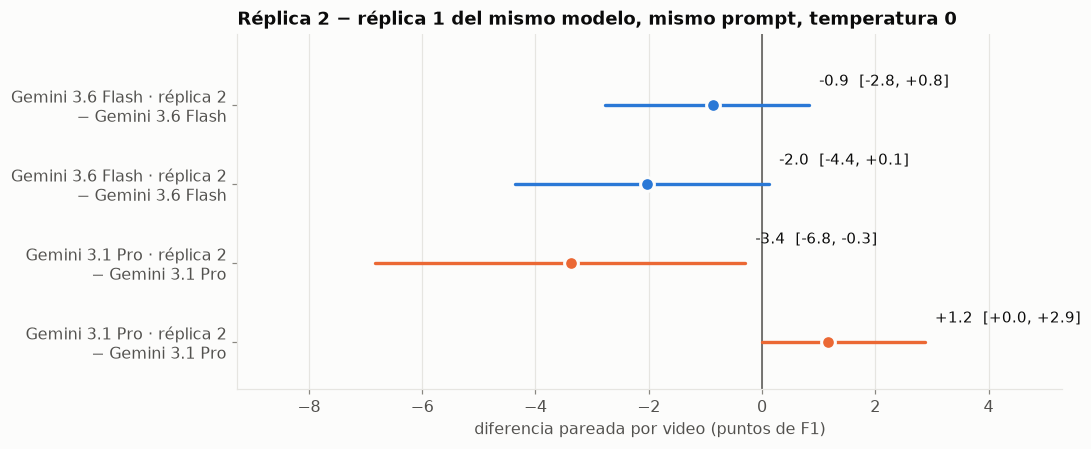

In [7]:
pares = [p for p in [("A_flash", "A_flash_rep2"), ("B_flash", "B_flash_rep2"), ("B_pro", "B_pro_rep2"), ("Bwm_pro", "Bwm_pro_rep2")]
         if c.existe(p[1])]
fig, ax = plt.subplots(figsize=(10, 4.2))
c.bosque(ax, pares, titulo="Réplica 2 − réplica 1 del mismo modelo, mismo prompt, temperatura 0")
fig.tight_layout()
c.guardar(fig, "H5_ruido_entre_replicas")
c.tabla_pareada(pares)

## 4 · El efecto de quitar la pizarra y el transcript, réplica por réplica

comparación (B − A),Δ,IC 95 %,gana / pierde / empata,p (signos)
Gemini 3.1 Pro − Gemini 3.1 Pro,+16.10,"[+9.53, +23.03]",23 / 5 / 2,0.001
Gemini 3.1 Pro · réplica 2 − Gemini 3.1 Pro · réplica 2,+20.63,"[+14.55, +27.23]",26 / 2 / 2,0.000
Gemini 3.1 Pro − Gemini 3.6 Flash,+4.24,"[+0.01, +8.31]",15 / 5 / 10,0.041
Gemini 3.1 Pro · réplica 2 − Gemini 3.6 Flash,+5.41,"[+1.77, +9.21]",15 / 5 / 10,0.041


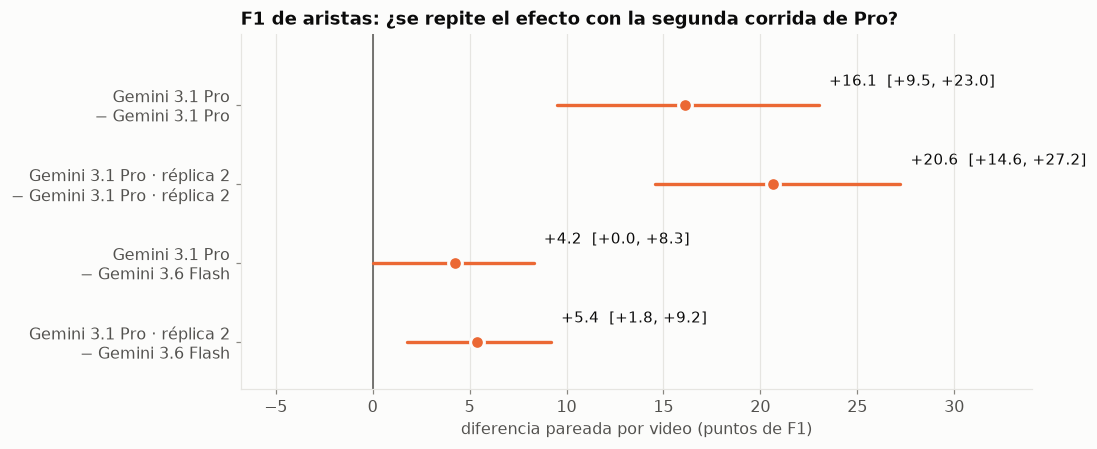

In [8]:
pares = [p for p in [("B_pro", "Bwm_pro"), ("B_pro_rep2", "Bwm_pro_rep2"), ("Bwm_flash", "Bwm_pro"), ("Bwm_flash", "Bwm_pro_rep2")]
         if c.existe(p[0]) and c.existe(p[1])]
fig, ax = plt.subplots(figsize=(10, 4.2))
c.bosque(ax, pares, titulo="F1 de aristas: ¿se repite el efecto con la segunda corrida de Pro?")
fig.tight_layout()
c.guardar(fig, "H5_efecto_replicado")
c.tabla_pareada(pares)

## Qué aporta al paper

- **El ruido de Pro es mayor cuando tiene entradas que se contradicen** (3,4 puntos entre
  corridas) que cuando solo recibe el World Model (1,2). Aun así es cinco veces menor que el
  efecto de quitar la pizarra y el transcript.
- **Con solo el World Model, Pro supera a Flash** en sus dos corridas (+4,24 y +5,41, los dos
  intervalos fuera del cero). Flash tiene una sola corrida en esa condición, así que falta su
  réplica para afirmarlo.
- **Lectura para la tesis del paper:** un modelo que se apoya más en la pizarra y la narración
  se aleja más de la referencia, que es lo esperable si la topología de la referencia no está
  dibujada.

**Lo que no está probado.** Que las reglas del prompt ("Audio-Driven Expansion", "Visual &
Verbal Grounding") sean lo que empuja a Pro a rehacer el grafo: es una lectura del razonamiento
y de los conteos. Lo separa el experimento del prompt mínimo, que no se corrió.